# Deteksi Penipuan Pembukaan Rekening Bank (Bank Account Fraud)

**Studi Kasus:** Bank Account Fraud (BAF) — Varian Base (Bulan 0–3)  
**Tujuan:** Membangun sistem deteksi dini pengajuan rekening palsu/fraud dengan kendala operasional ketat, yaitu tingkat kesalahan penuduhan nasabah wajar (*False Positive Rate* / FPR) dibatasi **maksimal 5%**.  
**Metrik Utama:** True Positive Rate (TPR) pada False Positive Rate (FPR) $\le 5\%$.

---

### Konteks Permasalahan
Pada perbankan digital, pengajuan rekening secara online rentan dimanfaatkan pelaku kejahatan untuk membuka akun fiktif (*synthetic identity*) atau akun penampung dana kejahatan (*money mule*). Namun, sistem tidak dapat memblokir pengajuan secara agresif tanpa memperhitungkan dampaknya terhadap nasabah wajar. Setiap nasabah wajar yang keliru ditandai menimbulkan friksi layanan, potensi kehilangan calon pelanggan (*customer churn*), serta pembengkakan biaya operasional verifikasi manual. Oleh karena itu, optimasi model difokuskan pada penangkapan sebanyak mungkin penipuan dalam ambang batas toleransi FPR $\le 5\%$.


## 1. Inisialisasi Lingkungan dan Library

Modul yang digunakan meliputi:
* `pandas` dan `numpy` untuk manipulasi data tabular dan komputasi numerik.
* `lightgbm` sebagai algoritma *Gradient Boosted Decision Trees* (GBDT) utama.
* `scikit-learn` untuk *encoding* variabel kategorikal serta kalkulasi kurva evaluasi (*ROC curve* dan *AUC*).
* `matplotlib` untuk visualisasi kurva performa model.
* `joblib` untuk serialisasi artefak model dan komponen *pipeline*.


In [1]:
import os
import urllib.request
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import joblib

from sklearn.preprocessing import OrdinalEncoder
from sklearn.metrics import roc_curve, roc_auc_score, confusion_matrix
import lightgbm as lgb

# Konfigurasi format tampilan angka desimal
pd.set_option('display.float_format', lambda x: '%.4f' % x)
print("Inisialisasi library selesai.")


Inisialisasi library selesai.


## 2. Pemuatan Dataset

Dataset yang digunakan adalah **Bank Account Fraud (BAF) varian Base** pada rentang **bulan 0 sampai 3**. Jika berkas belum tersedia secara lokal, sistem akan mengunduh dan menyaring data secara bertahap (*chunking*) untuk memastikan efisiensi memori.


In [2]:
os.makedirs('data', exist_ok=True)
data_path = 'data/Base_month_0_3.csv'

# Download otomatis jika data belum tersedia lokal
if not os.path.exists(data_path):
    print("Mengunduh dataset BAF Base (Bulan 0-3)...")
    url = "https://huggingface.co/datasets/jAEhEEkIM/operationbench-baf-raw/resolve/main/Base.csv"
    chunks = []
    # Baca bertahap (chunking) agar hemat memori
    for chunk in pd.read_csv(url, chunksize=100000):
        filtered = chunk[chunk['month'] <= 3]
        if not filtered.empty:
            chunks.append(filtered)
        if (chunk['month'] > 3).all():
            break
    df = pd.concat(chunks, ignore_index=True)
    df.to_csv(data_path, index=False)
    print("Pemuatan dan penyimpanan dataset selesai.")
else:
    print("Membaca dataset dari direktori lokal...")
    df = pd.read_csv(data_path)

print(f"Total baris data: {len(df):,} baris")
print(f"Total kolom: {df.shape[1]} kolom")
df.head(3)


Membaca dataset dari direktori lokal...


Total baris data: 547,975 baris
Total kolom: 32 kolom


,fraud_bool,income,name_email_similarity,prev_address_months_count,current_address_months_count,customer_age,days_since_request,intended_balcon_amount,payment_type,zip_count_4w,...,has_other_cards,proposed_credit_limit,foreign_request,source,session_length_in_minutes,device_os,keep_alive_session,device_distinct_emails_8w,device_fraud_count,month
0,0,0.3000,0.9865,-1,25,40,0.0067,102.4537,AA,1059,...,0,1500.0000,0,INTERNET,16.2248,linux,1,1,0,0
1,0,0.8000,0.6174,-1,89,20,0.0101,-0.8496,AD,1658,...,0,1500.0000,0,INTERNET,3.3639,other,1,1,0,0
2,0,0.8000,0.9967,9,14,40,0.0123,-1.4904,AB,1095,...,0,200.0000,0,INTERNET,22.7306,windows,0,1,0,0


## 3. Eksplorasi Data Singkat

Eksplorasi awal difokuskan pada pemeriksaan distribusi volume observasi per bulan dan proporsi label target (`fraud_bool`) guna memahami tingkat ketidakseimbangan kelas (*class imbalance*).


In [3]:
print("--- Distribusi Observasi per Bulan ---")
print(df['month'].value_counts().sort_index())

print("\n--- Proporsi Label Target (0 = Wajar, 1 = Fraud) ---")
fraud_counts = df['fraud_bool'].value_counts()
print(f"Nasabah Wajar (0)   : {fraud_counts[0]:,} ({fraud_counts[0]/len(df)*100:.2f}%)")
print(f"Fraud / Penipuan (1): {fraud_counts[1]:,} ({fraud_counts[1]/len(df)*100:.2f}%)")


--- Distribusi Observasi per Bulan ---
month
0    132440
1    127620
2    136979
3    150936
Name: count, dtype: int64

--- Proporsi Label Target (0 = Wajar, 1 = Fraud) ---
Nasabah Wajar (0)   : 542,687 (99.03%)
Fraud / Penipuan (1): 5,288 (0.97%)


## 4. Pembagian Data Latih dan Validasi (*Temporal Split*)

Dataset dipartisi menggunakan pendekatan berbasis waktu (*Out-of-Time / Temporal Split*):
* **Data Latih (Train):** Bulan 0, 1, dan 2 (397.039 baris / 72,5%)
* **Data Validasi (Validation):** Bulan 3 (150.936 baris / 27,5%)

**Rasional Pemilihan Strategi:**
1. **Mencegah Kebocoran Informasi Temporal (*Data Leakage / Lookahead Bias*):** Pembagian secara acak (*random split*) tidak merepresentasikan operasional nyata perbankan karena model dapat mempelajari pola dari masa depan untuk menebak masa lalu.
2. **Mengantisipasi Pergeseran Konsep (*Concept Drift*):** Pola dan taktik fraud terus berevolusi seiring berjalannya waktu. Melatih model pada riwayat masa lalu (bulan 0–2) dan mengujinya pada periode waktu berikutnya (bulan 3) memberikan estimasi performa generalisasi yang realistis saat model dideploy ke produksi.


In [4]:
train_df = df[df['month'] < 3].copy()
val_df = df[df['month'] == 3].copy()

print(f"Jumlah Data Latih (Bulan 0-2)   : {len(train_df):,} baris ({len(train_df)/len(df)*100:.1f}%)")
print(f"Jumlah Data Validasi (Bulan 3) : {len(val_df):,} baris ({len(val_df)/len(df)*100:.1f}%)")


Jumlah Data Latih (Bulan 0-2)   : 397,039 baris (72.5%)
Jumlah Data Validasi (Bulan 3) : 150,936 baris (27.5%)


## 5. Pra-pemrosesan Data

Terdapat 5 fitur bertipe teks/kategorikal: `payment_type`, `employment_status`, `housing_status`, `source`, dan `device_os`.
Transformasi dilakukan dengan **Ordinal Encoding**. Objek *encoder* hanya di-*fit* menggunakan data latih (bulan 0–2), kemudian digunakan untuk mentransformasi data latih maupun data validasi guna menjaga integritas evaluasi tanpa kebocoran data.

Kolom `month` dan label target `fraud_bool` dipisahkan dari matriks fitur prediktor ($X$).


In [5]:
categorical_cols = ['payment_type', 'employment_status', 'housing_status', 'source', 'device_os']
feature_cols = [c for c in df.columns if c not in ['fraud_bool', 'month']]

# Transformasi fitur kategorikal dengan OrdinalEncoder
encoder = OrdinalEncoder(handle_unknown='use_encoded_value', unknown_value=-1)

# Fit hanya pada data latih, transform pada data latih dan validasi
train_df[categorical_cols] = encoder.fit_transform(train_df[categorical_cols].astype(str))
val_df[categorical_cols] = encoder.transform(val_df[categorical_cols].astype(str))

# Ekstraksi matriks fitur (X) dan target (y)
X_train = train_df[feature_cols]
y_train = train_df['fraud_bool']

X_val = val_df[feature_cols]
y_val = val_df['fraud_bool']

print(f"Total fitur prediktor: {len(feature_cols)}")
print("Contoh 5 fitur pertama:", feature_cols[:5])


Total fitur prediktor: 30
Contoh 5 fitur pertama: ['income', 'name_email_similarity', 'prev_address_months_count', 'current_address_months_count', 'customer_age']


## 6. Pelatihan Model Klasifikasi (LightGBM)

Algoritma **LightGBM (Light Gradient Boosting Machine)** dipilih atas pertimbangan:
* **Keunggulan pada Data Tabular Imbalanced:** Struktur *decision tree* berbasis gradient boosting secara konsisten menjadi standar terbaik pada data tabular finansial dengan prevalensi kelas positif yang sangat rendah (~1% fraud).
* **Efisiensi Komputasi:** Pemanfaatan algoritma *histogram-based* memungkinkan pelatihan ratusan ribu observasi selesai dalam waktu singkat tanpa ketergantungan komputasi GPU.
* **Kalibrasi Probabilitas yang Halus:** Menghasilkan skor probabilitas yang kontinu dan terkalibrasi dengan baik, memudahkan penentuan ambang batas keputusan (*decision threshold*) yang presisi.


In [6]:
# Inisialisasi model LightGBM dengan konfigurasi standar yang stabil
model = lgb.LGBMClassifier(
    n_estimators=300,
    learning_rate=0.05,
    num_leaves=31,
    random_state=42,
    verbose=-1
)

print("Memulai pelatihan model LightGBM...")
model.fit(X_train, y_train)
print("Pelatihan model selesai.")


Memulai pelatihan model LightGBM...


Pelatihan model selesai.


## 7. Evaluasi dan Penetapan Batas Ambang Keputusan (TPR pada FPR $\le$ 5%)

Prosedur evaluasi dilakukan sebagai berikut:
1. Model menghasilkan skor estimasi probabilitas risiko fraud untuk seluruh sampel pada data validasi (bulan 3).
2. Kurva *Receiver Operating Characteristic* (ROC) dikomputasi untuk memetakan seluruh kombinasi *False Positive Rate* (FPR) dan *True Positive Rate* (TPR) di berbagai nilai ambang batas (*threshold*).
3. Ambang batas keputusan dipilih secara spesifik pada titik tertinggi di mana rasio nasabah wajar yang salah ditandai (FPR) tetap berada pada ambang batas operasional $\le 5\%$.
4. Performa dilaporkan berdasarkan persentase penipu yang berhasil terjaring (**TPR**) pada batas toleransi kesalahan tersebut.


In [7]:
# 1. Prediksi estimasi probabilitas fraud pada data validasi
val_probs = model.predict_proba(X_val)[:, 1]

# 2. Komputasi kurva ROC dan skor AUC
fpr, tpr, thresholds = roc_curve(y_val, val_probs)
auc_score = roc_auc_score(y_val, val_probs)

# 3. Identifikasi indeks ambang batas pada FPR <= 5% (0.05)
idx_5pct = np.where(fpr <= 0.05)[0][-1]

best_threshold = float(thresholds[idx_5pct])
final_fpr = float(fpr[idx_5pct])
final_tpr = float(tpr[idx_5pct])

print("=" * 55)
print("           HASIL EVALUASI DATA VALIDASI (BULAN 3)")
print("=" * 55)
print(f"ROC-AUC Score                  : {auc_score:.4f}")
print(f"Batas Ambang (Threshold)       : {best_threshold:.4f}")
print(f"False Positive Rate (FPR)      : {final_fpr * 100:.2f}%  (Syarat: <= 5.0%)")
print(f"True Positive Rate (TPR)       : {final_tpr * 100:.2f}%")
print("=" * 55)


           HASIL EVALUASI DATA VALIDASI (BULAN 3)
ROC-AUC Score                  : 0.9100
Batas Ambang (Threshold)       : 0.0523
False Positive Rate (FPR)      : 4.98%  (Syarat: <= 5.0%)
True Positive Rate (TPR)       : 56.54%


### Confusion Matrix pada Threshold Operasional

Tabel berikut menampilkan distribusi prediksi model terhadap label aktual saat ambang batas keputusan dikunci pada nilai threshold yang menghasilkan FPR $\le$ 5%. Keempat kuadran (*True Positive*, *False Positive*, *True Negative*, *False Negative*) memberikan gambaran konkret mengenai jumlah absolut nasabah yang terdampak oleh keputusan model.


         CONFUSION MATRIX (THRESHOLD = 0.0523)
  True Negative  (TN) : 142,093  — nasabah wajar, lolos otomatis
  False Positive (FP) :   7,451  — nasabah wajar, keliru ditandai
  False Negative (FN) :     605  — fraud, lolos dari deteksi
  True Positive  (TP) :     787  — fraud, berhasil tertangkap

  Total data validasi : 150,936
  Akurasi keseluruhan : 94.66%


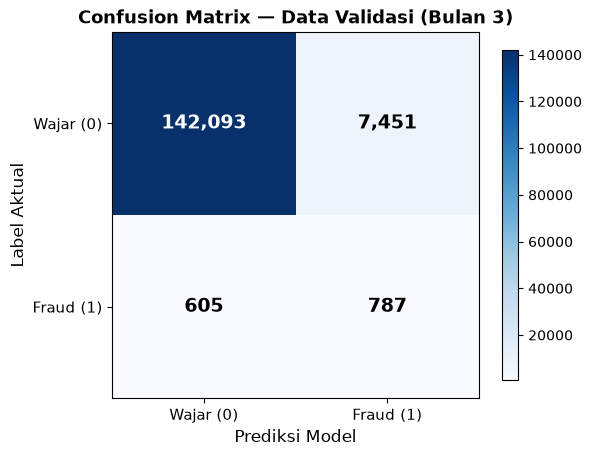

In [8]:
# Konversi probabilitas menjadi prediksi biner berdasarkan threshold operasional
val_preds = (val_probs >= best_threshold).astype(int)

# Komputasi confusion matrix: [[TN, FP], [FN, TP]]
cm = confusion_matrix(y_val, val_preds)
tn, fp, fn, tp = cm.ravel()

print("=" * 55)
print("         CONFUSION MATRIX (THRESHOLD = {:.4f})".format(best_threshold))
print("=" * 55)
print(f"  True Negative  (TN) : {tn:>7,}  — nasabah wajar, lolos otomatis")
print(f"  False Positive (FP) : {fp:>7,}  — nasabah wajar, keliru ditandai")
print(f"  False Negative (FN) : {fn:>7,}  — fraud, lolos dari deteksi")
print(f"  True Positive  (TP) : {tp:>7,}  — fraud, berhasil tertangkap")
print("=" * 55)
print(f"\n  Total data validasi : {len(y_val):,}")
print(f"  Akurasi keseluruhan : {(tp + tn) / len(y_val) * 100:.2f}%")

# Visualisasi confusion matrix sebagai heatmap
fig, ax = plt.subplots(figsize=(6, 5))
im = ax.imshow(cm, cmap='Blues', interpolation='nearest')

labels = ['Wajar (0)', 'Fraud (1)']
ax.set_xticks([0, 1])
ax.set_yticks([0, 1])
ax.set_xticklabels(labels, fontsize=11)
ax.set_yticklabels(labels, fontsize=11)
ax.set_xlabel('Prediksi Model', fontsize=12)
ax.set_ylabel('Label Aktual', fontsize=12)
ax.set_title('Confusion Matrix — Data Validasi (Bulan 3)', fontsize=13, fontweight='bold')

# Annotasi angka di setiap kuadran
for i in range(2):
    for j in range(2):
        color = 'white' if cm[i, j] > cm.max() / 2 else 'black'
        ax.text(j, i, f'{cm[i, j]:,}', ha='center', va='center',
                fontsize=14, fontweight='bold', color=color)

plt.colorbar(im, ax=ax, shrink=0.8)
plt.tight_layout()
plt.show()


## 8. Visualisasi Kurva ROC dan Titik Operasional

Grafik kurva ROC di bawah ini memperlihatkan trade-off antara FPR dan TPR. Titik penanda menunjukkan performa operasional model saat batas toleransi kesalahan nasabah wajar dikunci pada nilai maksimal 5%.


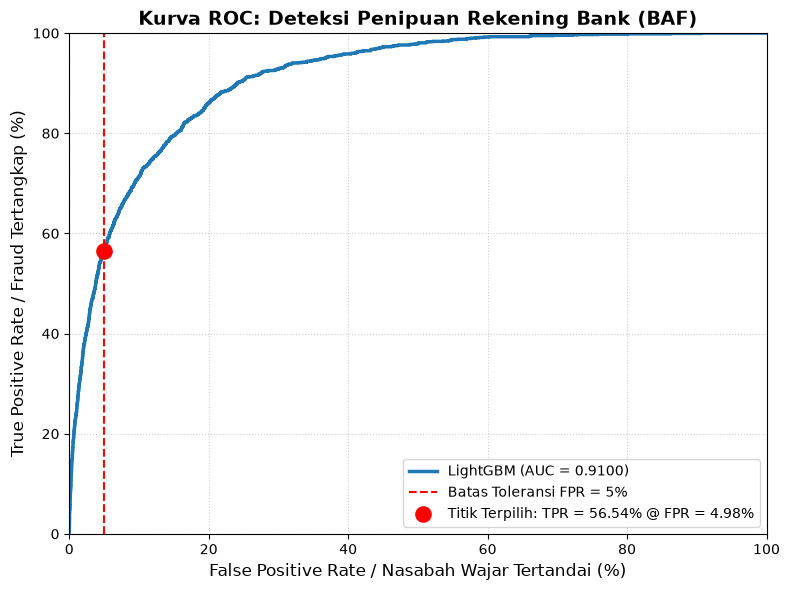

In [9]:
plt.figure(figsize=(8, 6))
plt.plot(fpr * 100, tpr * 100, color='#1f77b4', lw=2.5, label=f'LightGBM (AUC = {auc_score:.4f})')
plt.axvline(x=5.0, color='red', linestyle='--', label='Batas Toleransi FPR = 5%')
plt.scatter([final_fpr * 100], [final_tpr * 100], color='red', s=120, zorder=5, 
            label=f'Titik Terpilih: TPR = {final_tpr * 100:.2f}% @ FPR = {final_fpr * 100:.2f}%')

plt.title('Kurva ROC: Deteksi Penipuan Rekening Bank (BAF)', fontsize=14, fontweight='bold')
plt.xlabel('False Positive Rate / Nasabah Wajar Tertandai (%)', fontsize=12)
plt.ylabel('True Positive Rate / Fraud Tertangkap (%)', fontsize=12)
plt.xlim([0, 100])
plt.ylim([0, 100])
plt.grid(True, linestyle=':', alpha=0.6)
plt.legend(loc='lower right', fontsize=10)
plt.tight_layout()
plt.show()


## 9. Penyimpanan Artefak Model

Seluruh komponen yang dibutuhkan dalam pipeline inferensi disimpan dalam berkas serialisasi tunggal (`model/fraud_detector_lgbm.joblib`), meliputi:
* Model LightGBM yang telah dilatih
* Objek `OrdinalEncoder` untuk transformasi fitur kategorikal
* Metadata daftar kolom prediktor
* Nilai ambang batas operasional terkalibrasi (FPR $\le$ 5%)
* Metrik evaluasi validasi


In [10]:
os.makedirs('model', exist_ok=True)
model_path = 'model/fraud_detector_lgbm.joblib'

model_bundle = { 
    'model': model,
    'encoder': encoder,
    'categorical_cols': categorical_cols,
    'feature_cols': feature_cols,
    'threshold': best_threshold,
    'metrics': {
        'auc': auc_score,
        'fpr_at_5pct': final_fpr,
        'tpr_at_5pct': final_tpr
    }
}

joblib.dump(model_bundle, model_path)
file_size_mb = os.path.getsize(model_path) / (1024 * 1024)
print(f"Model berhasil disimpan di: {model_path}")
print(f"Ukuran berkas model: {file_size_mb:.2f} MB")


Model berhasil disimpan di: model/fraud_detector_lgbm.joblib
Ukuran berkas model: 1.00 MB


## 10. Verifikasi Pemuatan Ulang dan Pengujian Inferensi

Tahap ini memverifikasi bahwa berkas model yang disimpan dapat dimuat kembali secara independen dan langsung digunakan untuk mengevaluasi data pengajuan baru secara konsisten.


In [11]:
# 1. Pemuatan ulang artefak model dari disk
loaded_bundle = joblib.load(model_path)
print("Artefak model berhasil dimuat kembali.")
print(f"Threshold operasional tersimpan: {loaded_bundle['threshold']:.4f}")

# 2. Fungsi inferensi untuk evaluasi pengajuan baru
def predict_application(application_data, bundle):
    """
    Menghitung estimasi skor probabilitas fraud dan menentukan status pengajuan
    berdasarkan batas ambang operasional yang telah dikalibrasi.
    """
    input_df = application_data[bundle['feature_cols']].copy()
    # Transformasi fitur kategori
    input_df[bundle['categorical_cols']] = bundle['encoder'].transform(
        input_df[bundle['categorical_cols']].astype(str)
    )
    # Estimasi probabilitas fraud
    fraud_prob = bundle['model'].predict_proba(input_df)[:, 1][0]
    
    is_fraud = fraud_prob >= bundle['threshold']
    status = "TINJAU MANUAL (Indikasi Fraud)" if is_fraud else "LOLOS OTOMATIS (Nasabah Wajar)"
    return fraud_prob, status

# 3. Uji coba inferensi pada sampel data validasi
sample_honest = val_df[val_df['fraud_bool'] == 0].iloc[[0]]
sample_fraud = val_df[val_df['fraud_bool'] == 1].iloc[[0]]

prob_honest, status_honest = predict_application(sample_honest, loaded_bundle)
prob_fraud, status_fraud = predict_application(sample_fraud, loaded_bundle)

print("\n--- Contoh Uji Coba 1 (Observasi Label 0 / Nasabah Wajar) ---")
print(f"Estimasi Probabilitas Fraud : {prob_honest * 100:.2f}%")
print(f"Keputusan Sistem            : {status_honest}")

print("\n--- Contoh Uji Coba 2 (Observasi Label 1 / Fraud) ---")
print(f"Estimasi Probabilitas Fraud : {prob_fraud * 100:.2f}%")
print(f"Keputusan Sistem            : {status_fraud}")


Artefak model berhasil dimuat kembali.
Threshold operasional tersimpan: 0.0523

--- Contoh Uji Coba 1 (Observasi Label 0 / Nasabah Wajar) ---
Estimasi Probabilitas Fraud : 0.13%
Keputusan Sistem            : LOLOS OTOMATIS (Nasabah Wajar)

--- Contoh Uji Coba 2 (Observasi Label 1 / Fraud) ---
Estimasi Probabilitas Fraud : 11.51%
Keputusan Sistem            : TINJAU MANUAL (Indikasi Fraud)
